<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/AnaliseOutliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset4.csv to Dataset4 (1).csv


,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


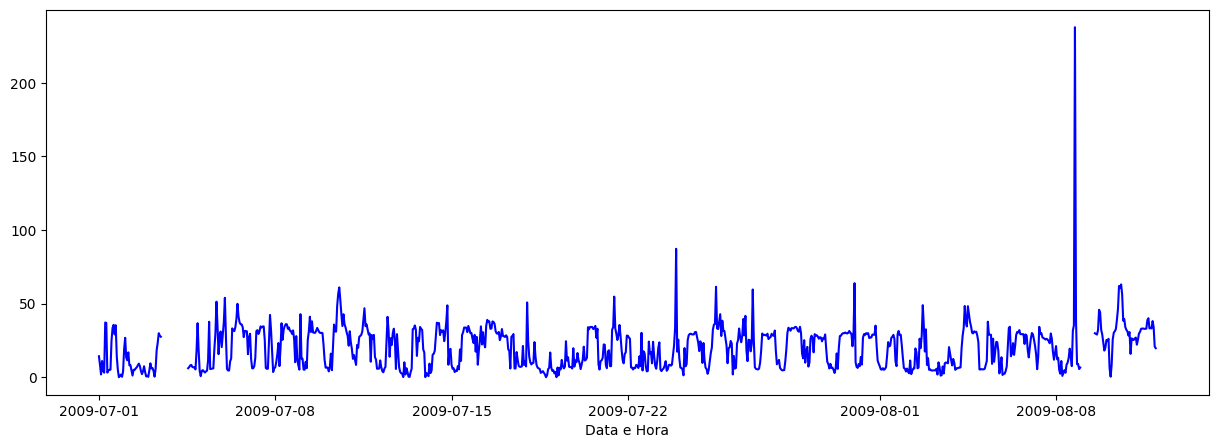

In [5]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

In [6]:
#Identificação de Outliers - Técnica Simples Baseada em Threshold
median = df['Preco'].median()
absolute_deviations = np.abs(df['Preco'] - median)
med = absolute_deviations.mean()
threshold = 8 * med
outliers = df['Preco'][df['Preco'] > threshold]
print(outliers)

DateTime
2009-08-08 18:00:00    237.76
Name: Preco, dtype: float64


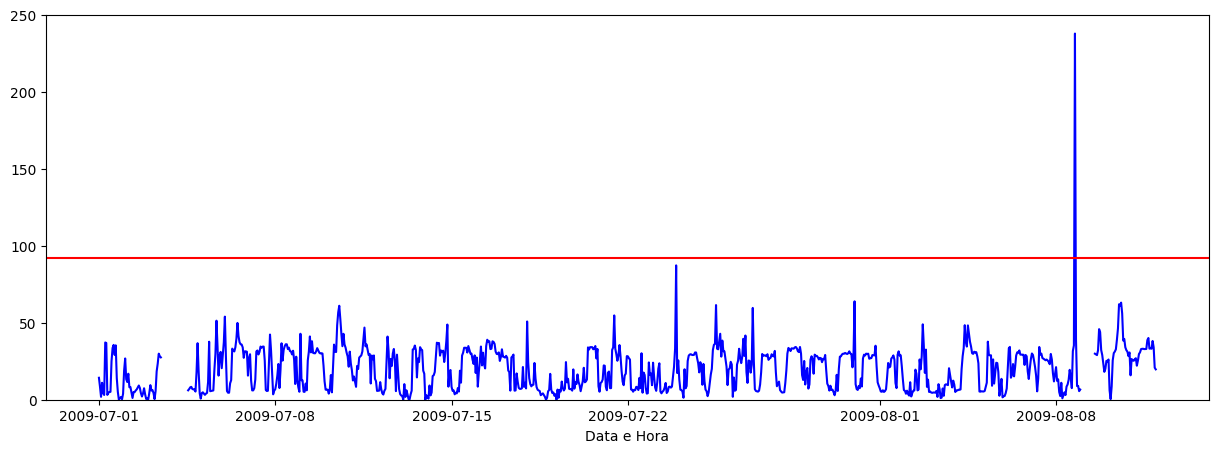

In [7]:
#Visualização do Threshold
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'], 'b')
plt.axhline(threshold, color='r', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylim(0, 250)
plt.show()

In [8]:
#Identificação de Outliers - Técnica Z-scores
mean = df['Preco'].mean()
std_dev = df['Preco'].std()
z_scores = (df['Preco'] - mean)/std_dev
threshold = 7 #Quanto maior o valor, significa que mais longe a amostra está da média
outliers = df['Preco'][z_scores > threshold]
print(outliers)

DateTime
2009-08-08 18:00:00    237.76
Name: Preco, dtype: float64


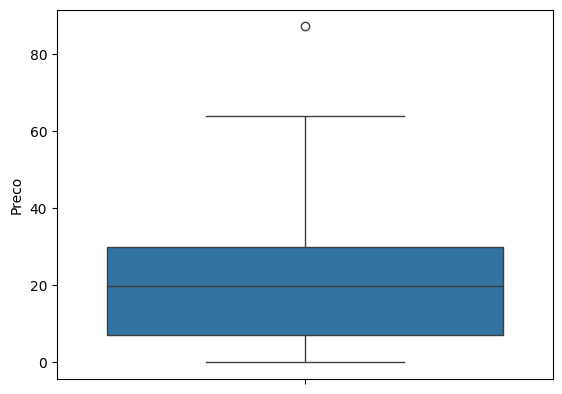

In [9]:
#Remove Outlier a partir de Z-scores
df_clean1 = df.drop(outliers.index)
sns.boxplot(df_clean1['Preco']);

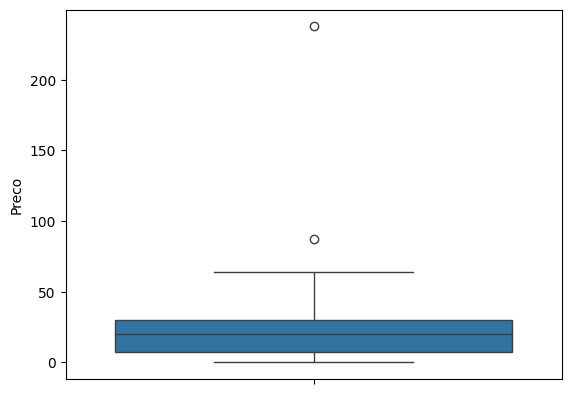

In [10]:
#Identificação de Outliers por Box-Plot
sns.boxplot(df['Preco']);

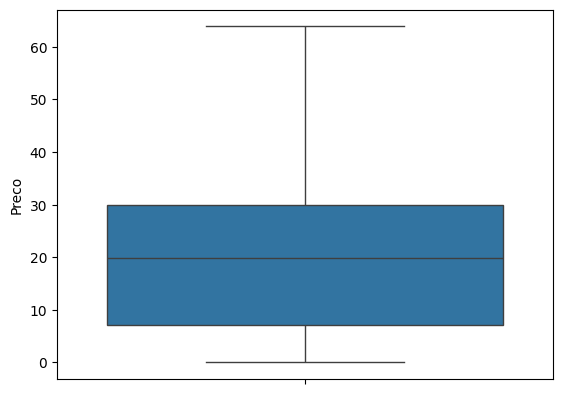

In [11]:
#Remove Outlier a partir da Visualização do Box-Plot
df_clean2 = df[df['Preco'] <= 80]
sns.boxplot(df_clean2['Preco']);

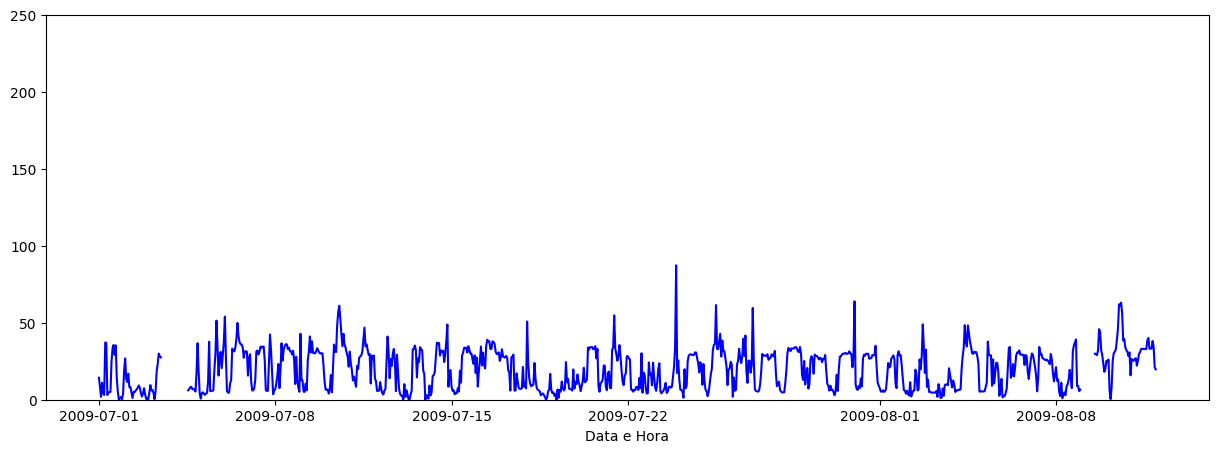

In [12]:
#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df_clean1['DateTime'], df_clean1['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.ylim(0, 250)
plt.show()

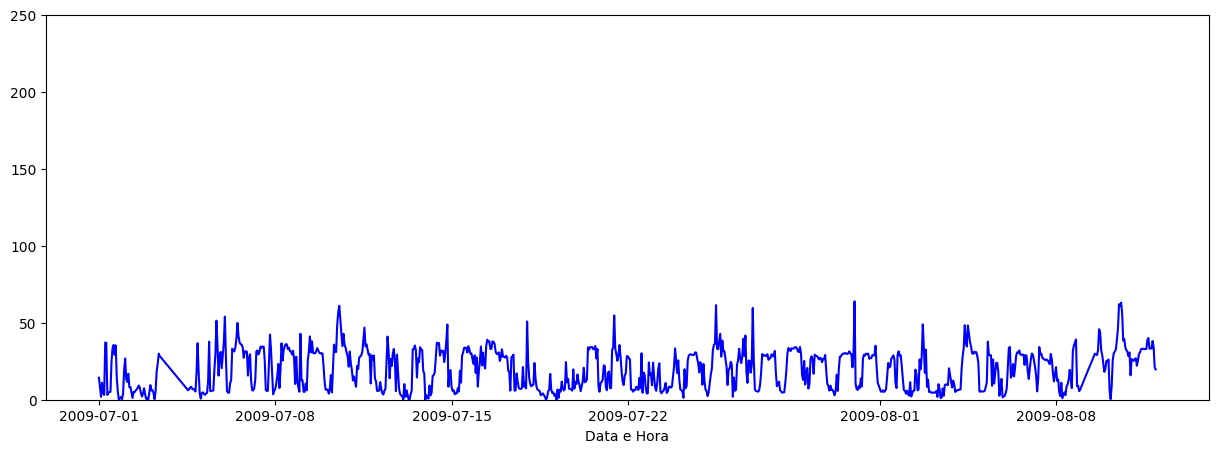

In [13]:
#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df_clean2['DateTime'], df_clean2['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.ylim(0, 250)
plt.show()

In [14]:
#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
#df_clone1 = df[:]
#df_clone1['Preco'] = df['Preco'] / df['Preco'].iloc[0]

df_clone1 = df_clean1[:]
df_clone1['Preco'] = df_clean1['Preco'] / df_clean1['Preco'].iloc[0]

df_clone2 = df_clean2[:]
df_clone2['Preco'] = df_clean2['Preco'] / df_clean2['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm1 = df_clone1[['Preco']]
df_norm2 = df_clone2[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged1 = df_norm1[:]
df_lagged2 = df_norm2[:]

#Determina os atrasos (em amostras)
lags = (1, 2)

#Gera o DataFrame com as Colunas de Atraso
df_lagged1 = df_norm1.assign(**{f'{col}_t-{lag}': df_norm1[col].shift(lag) for lag in lags for col in df_norm1})
df_lagged2 = df_norm2.assign(**{f'{col}_t-{lag}': df_norm2[col].shift(lag) for lag in lags for col in df_norm2})

#Exclui valor NaN
df_proc1 = df_lagged1.dropna()
df_proc2 = df_lagged2.dropna()

In [15]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc1.columns[[1]]
features

Index(['Preco_t-1'], dtype='object')

In [16]:
#Define a coluna que será variável de saída - interesse
target = df_proc1.columns[[0]]
target

Index(['Preco'], dtype='object')

In [17]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste1 = df_proc1['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao1 = df_proc1['2009-08-01 00:00:00':].index.values
df_dados_ajuste1 = df_proc1['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao1 = df_proc1['2009-08-01 00:00:00':]

df_t_ajuste2 = df_proc2['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao2 = df_proc2['2009-08-01 00:00:00':].index.values
df_dados_ajuste2 = df_proc2['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao2 = df_proc2['2009-08-01 00:00:00':]

X_ajuste1 = df_dados_ajuste1[features].values
Y_ajuste1 = df_dados_ajuste1[target].values
X_validacao1 = df_dados_validacao1[features].values
Y_validacao1 = df_dados_validacao1[target].values

X_ajuste2 = df_dados_ajuste2[features].values
Y_ajuste2 = df_dados_ajuste2[target].values
X_validacao2 = df_dados_validacao2[features].values
Y_validacao2 = df_dados_validacao2[target].values

In [18]:
# Parametrização de Modelo de Regressão Linear
from sklearn.linear_model import LinearRegression

modelo_RL1 = LinearRegression().fit(X_ajuste1, Y_ajuste1)
modelo_RL2 = LinearRegression().fit(X_ajuste2, Y_ajuste2)

In [19]:
#df_previsto_RL1 = modelo_RL1.predict(X_validacao1)
#df_previsto_RL1_denorm = df_previsto_RL1 * df['Preco'].iloc[0]

df_previsto_RL1 = modelo_RL1.predict(X_validacao1)
df_previsto_RL1_denorm = df_previsto_RL1 * df_clean1['Preco'].iloc[0]

df_previsto_RL2 = modelo_RL2.predict(X_validacao2)
df_previsto_RL2_denorm = df_previsto_RL2 * df_clean2['Preco'].iloc[0]

In [20]:
r_sq1 = modelo_RL1.score(X_validacao1, Y_validacao1)
print(f"R2: {r_sq1}")

r_sq2 = modelo_RL2.score(X_validacao2, Y_validacao2)
print(f"R2: {r_sq2}")

R2: 0.6646385562622121
R2: 0.6610199675493277


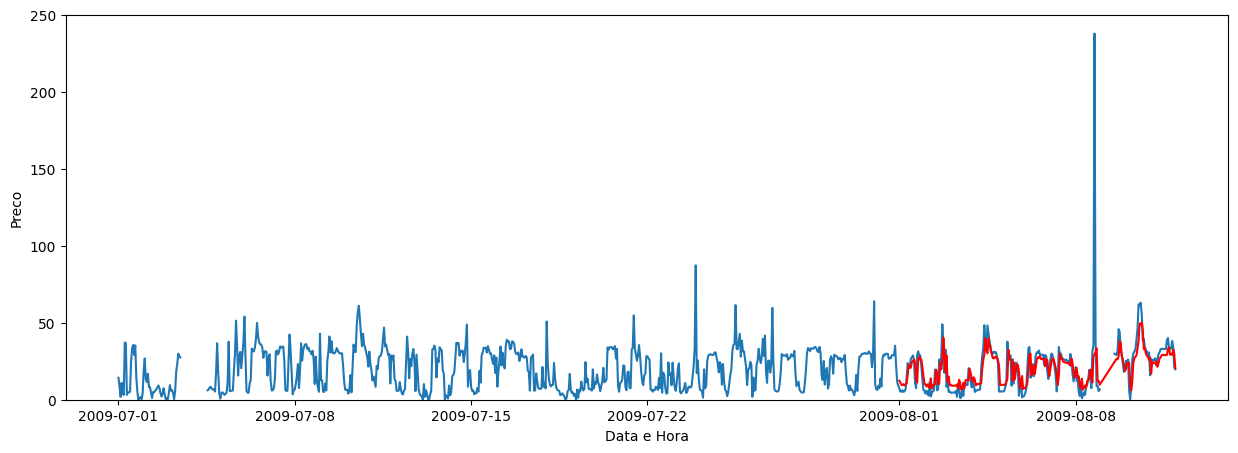

In [21]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RL1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.ylim(0, 250)
plt.show()

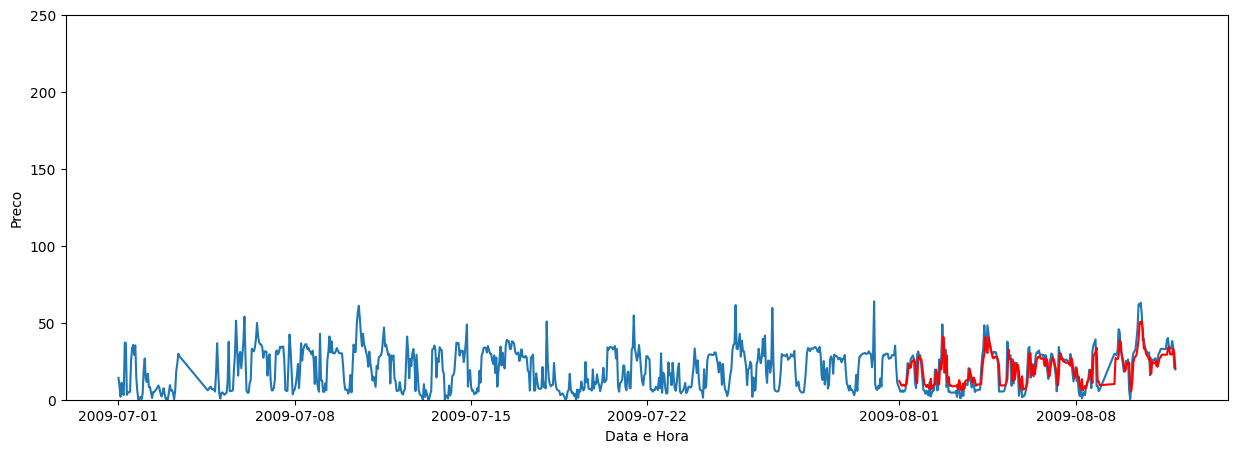

In [22]:
plt.figure(figsize=(15,5))
plt.plot(df_clean2['DateTime'], df_clean2['Preco'])
plt.plot(df_dados_validacao2.index, df_previsto_RL2_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.ylim(0, 250)
plt.show()

In [23]:
# Parametrização de Modelo de Regressão Polinomial
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

#Polinômio de grau = 1, então Polinomial = Linear
modelo_RP1 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=False))]).fit(X_ajuste1, Y_ajuste1)
modelo_RP2 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=False))]).fit(X_ajuste2, Y_ajuste2)

In [24]:
#df_previsto_RP1 = modelo_RP1.predict(X_validacao1)
#df_previsto_RP1_denorm = df_previsto_RP1 * df['Preco'].iloc[0]

df_previsto_RP1 = modelo_RP1.predict(X_validacao1)
df_previsto_RP1_denorm = df_previsto_RP1 * df_clean1['Preco'].iloc[0]

df_previsto_RP2 = modelo_RP2.predict(X_validacao2)
df_previsto_RP2_denorm = df_previsto_RP2 * df_clean2['Preco'].iloc[0]

In [25]:
r_sq1 = modelo_RP1.score(X_validacao1, Y_validacao1)
print(f"R2: {r_sq1}")

r_sq2 = modelo_RP2.score(X_validacao2, Y_validacao2)
print(f"R2: {r_sq2}")

R2: 0.6280503760373413
R2: 0.6300639204104925


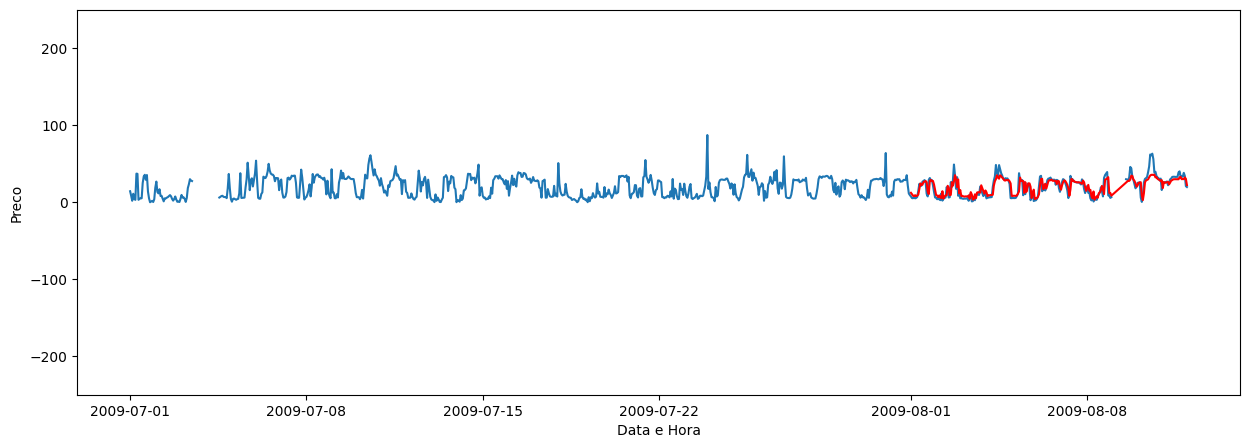

In [26]:
plt.figure(figsize=(15,5))
plt.plot(df_clean1['DateTime'], df_clean1['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RP1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.ylim(-250, 250)
plt.show()

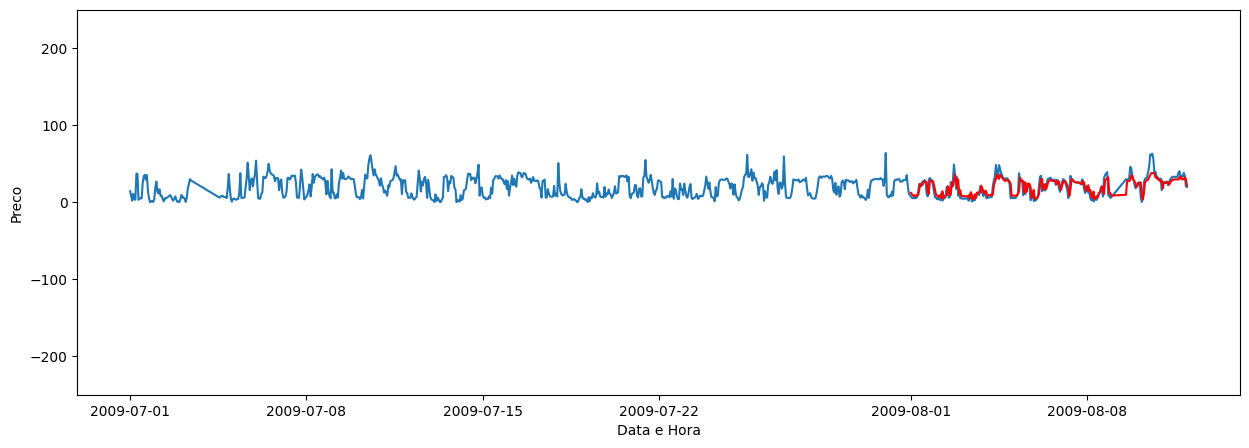

In [27]:
plt.figure(figsize=(15,5))
plt.plot(df_clean2['DateTime'], df_clean2['Preco'])
plt.plot(df_dados_validacao2.index, df_previsto_RP2_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.ylim(-250, 250)
plt.show()